In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn

# MODULE A: Dynamic Population-Based Outlier Detection
This module detects components whose measurements are abnormal relative to the healthy population (rather than relying on static datasheet limits). It uses an **Isolation Forest** machine learning model to find multivariate anomalies in the early-life data.

### 🟢 The Terms of PASS / FLAG (How the Logic Works)
**Problem Statement Alignment:** "Participants need to develop a 'Dynamic' outlier detection system. If a lot has an average leakage current of 10µA, a part showing 45 µA is a massive anomaly, even if the absolute datasheet maximum limit is 50 µA."

This module does exactly that: it ignores static absolute limits and evaluates if a component is behaving abnormally compared to the current population average.
* **The Algorithm:** It uses an unsupervised machine learning model called **Isolation Forest**.
* **The Terms:** The model evaluates early-life features to measure how mathematically 'isolated' a component is from the main herd's average behavior.
* **FLAG (Outlier):** If a component's measurements are so unusual that they land in the top 10% most isolated data points in the population (`contamination=0.10`), the algorithm assigns it an anomaly score of `-1` and FLAGS it (just like the 45µA example in a 10µA average lot).
* **PASS (Normal):** If the component's measurements sit tightly inside the dense cluster of normal average behavior exhibited by the other components, it receives an anomaly score of `1` and PASSES.


--- MODULE A: OUTLIER SCREENING RESULTS ---
Device_ID       Decision  Initial_RDS_Ohm  Early_Temp_Variance
        1  PASS (Normal)         0.826059          2081.182164
        2 FLAG (Outlier)         0.898155          3612.503019
        3  PASS (Normal)         0.882466           503.874976
        4  PASS (Normal)         0.907624           483.316427
        5  PASS (Normal)         0.900796           463.910051
        6  PASS (Normal)         0.847568          1193.164982
        7  PASS (Normal)         0.833334           158.226669
        8  PASS (Normal)         0.836629           151.505668
        9  PASS (Normal)         0.870411           187.057180
       10  PASS (Normal)         2.365818           164.803838
       11  PASS (Normal)         0.846481           259.969608
       12  PASS (Normal)         0.873536           182.759595
       13  PASS (Normal)         0.911800           475.413685
       14  PASS (Normal)         0.859833           150.710602
       15  

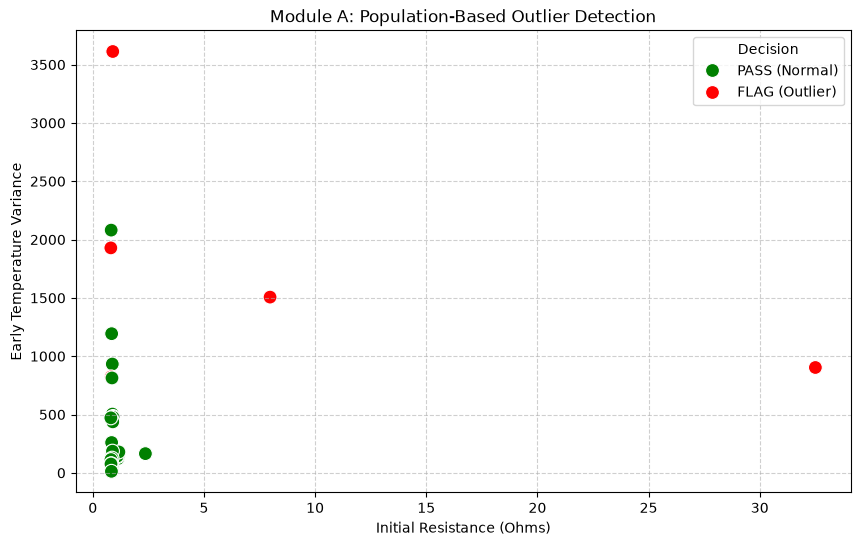

In [2]:
import pandas as pd
import numpy as np
import glob
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

# 1. Extract Early-Life Features for Population Comparison
file_paths = sorted(glob.glob('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_*.csv'))
population_data = []

for file_path in file_paths:
    try:
        df = pd.read_csv(file_path)
        df = df.dropna(subset=['Aging_Hours', 'RDS_on_Ohm', 'Package_Temp_C']).sort_values('Aging_Hours')
        if len(df) < 5: continue
            
        # Look only at the first few hours to emulate static screening timeframes (e.g., first 24h)
        early_df = df[df['Aging_Hours'] <= 24.0]
        if len(early_df) < 2: 
            early_df = df.head(10) # Fallback if component died very early
            
        population_data.append({
            'Device_ID': str(df['Device_ID'].iloc[0]),
            'Initial_RDS_Ohm': early_df['RDS_on_Ohm'].iloc[0],
            'Early_Max_RDS': early_df['RDS_on_Ohm'].max(),
            'Early_Temp_Variance': early_df['Package_Temp_C'].var(),
            'Early_RDS_Variance': early_df['RDS_on_Ohm'].var()
        })
    except Exception as e:
        pass

pop_df = pd.DataFrame(population_data).fillna(0)

# 2. Train Isolation Forest (Unsupervised Anomaly Detection)
# We assume approx 10% of components might be latent outliers
iso_forest = IsolationForest(contamination=0.10, random_state=42)

features = pop_df[['Initial_RDS_Ohm', 'Early_Max_RDS', 'Early_Temp_Variance', 'Early_RDS_Variance']]
pop_df['Anomaly_Score'] = iso_forest.fit_predict(features)
# Anomaly_Score: -1 means OUTLIER, 1 means INLIER

pop_df['Decision'] = pop_df['Anomaly_Score'].apply(lambda x: 'FLAG (Outlier)' if x == -1 else 'PASS (Normal)')

print("--- MODULE A: OUTLIER SCREENING RESULTS ---")
print(pop_df[['Device_ID', 'Decision', 'Initial_RDS_Ohm', 'Early_Temp_Variance']].to_string(index=False))

# 3. Visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(data=pop_df, x='Initial_RDS_Ohm', y='Early_Temp_Variance', hue='Decision', palette={'PASS (Normal)': 'green', 'FLAG (Outlier)': 'red'}, s=100)
plt.title('Module A: Population-Based Outlier Detection')
plt.xlabel('Initial Resistance (Ohms)')
plt.ylabel('Early Temperature Variance')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
